1. IMPORT LIBRARY

In [ ]:
import pandas as pd
import numpy as np

# preprocessing
from sklearn.preprocessing import StandardScaler

# PCA
from sklearn.decomposition import PCA

# KMeans
from sklearn.cluster import KMeans

# evaluasi
from sklearn.metrics import silhouette_score

# visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df.rename(columns={
    df.columns[0]: "Provinsi"
}, inplace=True)

**2. READ DATA (CSV)**

In [ ]:
# baca data
df = pd.read_csv('/content/data_TA_cleaned.csv')

# lihat data awal
print(df.head())
print(df.info())

df.rename(columns={
    df.columns[0]: "Provinsi"
}, inplace=True)

  Angka Harapan Lama Sekolah   RATA RATA LAMA SEKOLAH  \
0                    Provinsi              133.116053   
1                        ACEH              245.130000   
2              SUMATERA UTARA              338.320000   
3              SUMATERA BARAT              194.460000   
4                        RIAU              123.910000   

   Angka Partisipasi Kasar (APK) Menurut Provinsi dan Jenjang Pendidikan   \
0                                         105.472105                        
1                                         108.270000                        
2                                         106.040000                        
3                                         106.470000                        
4                                         107.920000                        

   Angka Partisipasi Murni (APM) Menurut Provinsi dan Jenjang Pendidikan   \
0                                          95.092105                        
1                                       

In [ ]:
df.set_index('Provinsi', inplace=True)

print(df.head())

                RATA RATA LAMA SEKOLAH  \
Provinsi                                 
Provinsi                    133.116053   
ACEH                        245.130000   
SUMATERA UTARA              338.320000   
SUMATERA BARAT              194.460000   
RIAU                        123.910000   

                Angka Partisipasi Kasar (APK) Menurut Provinsi dan Jenjang Pendidikan   \
Provinsi                                                                                 
Provinsi                                               105.472105                        
ACEH                                                   108.270000                        
SUMATERA UTARA                                         106.040000                        
SUMATERA BARAT                                         106.470000                        
RIAU                                                   107.920000                        

                Angka Partisipasi Murni (APM) Menurut Provinsi dan Jenjang

In [ ]:
print(df.columns)

Index(['Angka Harapan Lama Sekolah ', 'RATA RATA LAMA SEKOLAH',
       'Angka Partisipasi Kasar (APK) Menurut Provinsi dan Jenjang Pendidikan ',
       'Angka Partisipasi Murni (APM) Menurut Provinsi dan Jenjang Pendidikan ',
       'Angka Partisipasi Sekolah (APS) Menurut Provinsi dan Kelompok Umur ',
       'Persentase Penduduk 10 Tahun Ke Atas yang Tidak/Belum Pernah Sekolah menurut Provinsi 2025'],
      dtype='object')


In [ ]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print(df)

                      RATA RATA LAMA SEKOLAH  \
Provinsi                                       
Provinsi                          133.116053   
ACEH                              245.130000   
SUMATERA UTARA                    338.320000   
SUMATERA BARAT                    194.460000   
RIAU                              123.910000   
JAMBI                             111.440000   
SUMATERA SELATAN                  161.200000   
BENGKULU                          102.790000   
LAMPUNG                           141.320000   
KEP. BANGKA BELITUNG               70.410000   
KEPULAUAN RIAU                     77.740000   
DKI JAKARTA                        81.110000   
JAWA BARAT                        263.440000   
JAWA TENGAH                       316.680000   
D I YOGYAKARTA                     62.600000   
JAWA TIMUR                        350.810000   
BANTEN                             87.380000   
BALI                               99.020000   
NUSA TENGGARA BARAT               100.56

3. PREPROCESSING DATA

**3.1 Cek Missing Value**

In [ ]:
print(df.isnull().sum())

RATA RATA LAMA SEKOLAH                                                                        0
Angka Partisipasi Kasar (APK) Menurut Provinsi dan Jenjang Pendidikan                         0
Angka Partisipasi Murni (APM) Menurut Provinsi dan Jenjang Pendidikan                         0
Angka Partisipasi Sekolah (APS) Menurut Provinsi dan Kelompok Umur                            0
Persentase Penduduk 10 Tahun Ke Atas yang Tidak/Belum Pernah Sekolah menurut Provinsi 2025    0
dtype: int64


In [ ]:
df = df.fillna(df.mean(numeric_only=True))

3.2 Pisahkan Kolom Non-Numerik

In [ ]:
# simpan nama provinsi
provinsi_col_name = df.columns[0]
provinsi = df[provinsi_col_name]

# ambil data numerik saja
df_numeric = df.drop(columns=[provinsi_col_name])

3.3 Normalisasi / Standarisasi

PENTING untuk PCA & K-Means **teks tebal**

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_numeric)

4. PCA (REDUKSI DIMENSI)
4.1 Menentukan jumlah komponen

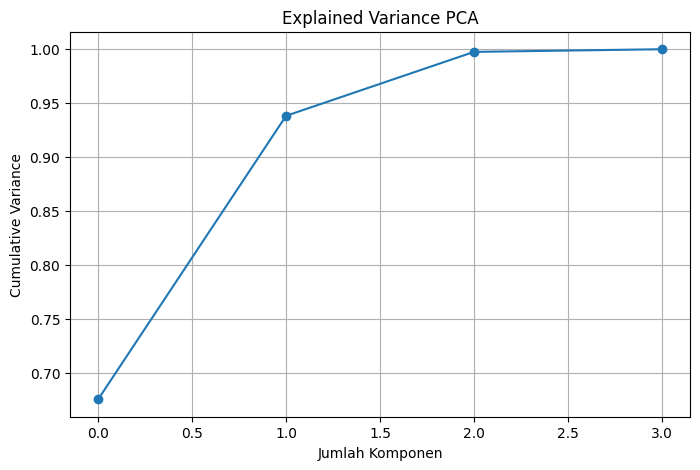

In [ ]:
pca = PCA()
pca.fit(X_scaled)

# variance ratio
explained_variance = pca.explained_variance_ratio_

# plot
plt.figure(figsize=(8,5))
plt.plot(np.cumsum(explained_variance), marker='o')
plt.xlabel('Jumlah Komponen')
plt.ylabel('Cumulative Variance')
plt.title('Explained Variance PCA')
plt.grid()
plt.show()

4.2 Ambil Komponen Utama (misal 2 komponen)

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained Variance:", pca.explained_variance_ratio_)

Explained Variance: [0.67585978 0.26247714]


**5. MENENTUKAN JUMLAH CLUSTER (ELBOW METHOD)**

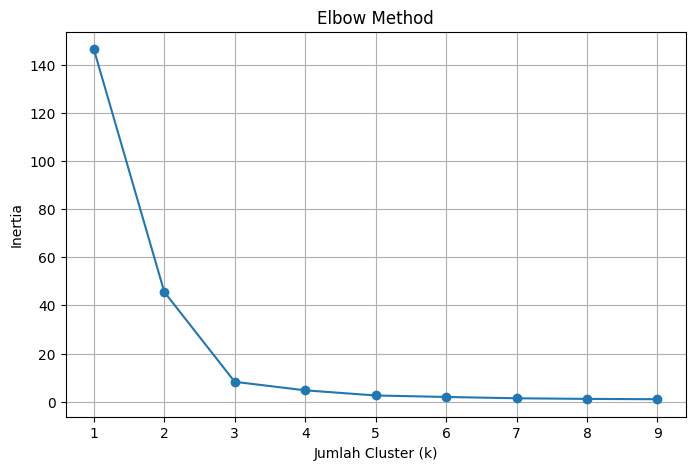

In [ ]:
inertia = []

K = range(1,10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_pca)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K, inertia, marker='o')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid()
plt.show()

6. K-MEANS CLUSTERING

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_pca)

7. EVALUASI CLUSTER

In [ ]:
score = silhouette_score(X_pca, clusters)
print("Silhouette Score:", score)

Silhouette Score: 0.8863071711394974


8. HASIL CLUSTER KE DATAFRAME

In [ ]:
df_result = pd.DataFrame(X_pca, columns=['PC1','PC2'])
df_result['Cluster'] = clusters
df_result['Provinsi'] = provinsi

print(df_result.head())

            PC1           PC2  Cluster  Provinsi
0  1.957721e-16  1.209780e-16        0       NaN
1  6.149593e-01 -3.964464e-01        0       NaN
2  3.860571e-01 -4.249900e-01        0       NaN
3  5.583684e-01 -4.379741e-01        0       NaN
4  7.598213e-01 -2.526738e-01        0       NaN


In [ ]:
df.head(50)   # tampil 50 baris

,RATA RATA LAMA SEKOLAH,Angka Partisipasi Kasar (APK) Menurut Provinsi dan Jenjang Pendidikan,Angka Partisipasi Murni (APM) Menurut Provinsi dan Jenjang Pendidikan,Angka Partisipasi Sekolah (APS) Menurut Provinsi dan Kelompok Umur,Persentase Penduduk 10 Tahun Ke Atas yang Tidak/Belum Pernah Sekolah menurut Provinsi 2025
Provinsi,,,,,
Provinsi,133.116053,105.472105,95.092105,98.057368,2.609412
ACEH,245.130000,108.270000,96.320000,99.380000,0.670000
SUMATERA UTARA,338.320000,106.040000,95.990000,99.540000,0.900000
SUMATERA BARAT,194.460000,106.470000,97.060000,99.630000,0.870000
RIAU,123.910000,107.920000,97.540000,99.740000,1.430000
JAMBI,111.440000,107.380000,97.020000,99.450000,1.340000
SUMATERA SELATAN,161.200000,107.690000,95.980000,99.500000,1.080000
BENGKULU,102.790000,106.860000,96.120000,99.290000,1.410000
LAMPUNG,141.320000,105.190000,97.640000,99.620000,1.020000


9. VISUALISASI CLUSTER

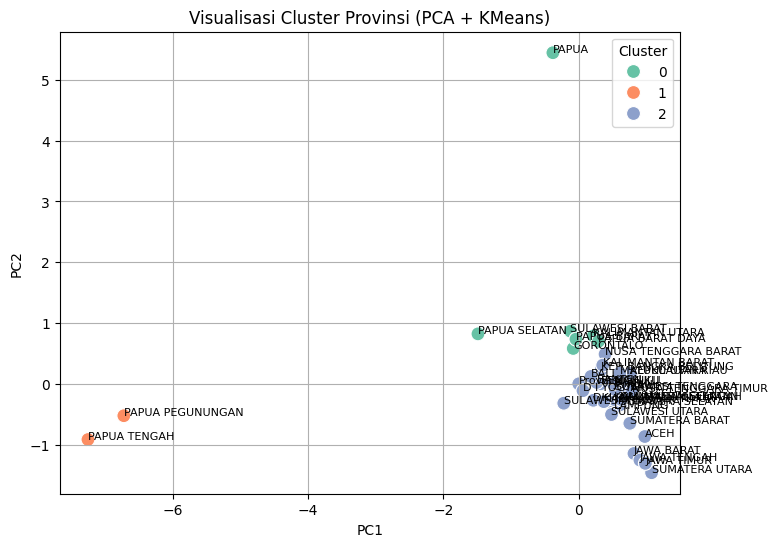

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Cluster',
    data=df_result,
    palette='Set2',
    s=100
)

# anotasi provinsi
for i in range(len(df_result)):
    plt.text(df_result['PC1'][i], df_result['PC2'][i], df_result['Provinsi'][i], fontsize=8)

plt.title('Visualisasi Cluster Provinsi (PCA + KMeans)')
plt.grid()
plt.show()

**10. ANALISIS KARAKTERISTIK CLUSTER**

In [ ]:
df['Cluster'] = clusters

# rata-rata tiap cluster
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)
print(cluster_summary)

         RATA RATA LAMA SEKOLAH  \
Cluster                           
0                     67.257143   
1                     30.900000   
2                    155.297535   

         Angka Partisipasi Kasar (APK) Menurut Provinsi dan Jenjang Pendidikan   \
Cluster                                                                           
0                                               108.627143                        
1                                                83.415000                        
2                                               106.206404                        

         Angka Partisipasi Murni (APM) Menurut Provinsi dan Jenjang Pendidikan   \
Cluster                                                                           
0                                                93.778571                        
1                                                73.700000                        
2                                                96.824737                  

In [ ]:
  print("Eigenvalues:", pca.explained_variance_)
print("Eigenvectors:\n", pca.components_)

Eigenvalues: [2.92268205 1.14715323]
Eigenvectors:
 [[ 0.27011189  0.50627621  0.57325049  0.58208532 -0.05731068]
 [-0.44318379  0.3279889  -0.03493808  0.03677946  0.83272925]]
